In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 25.7 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


--- [KOD 1] KLASİK SVM DENEYLERİ BAŞLATILIYOR (WINE - 3 SINIF) ---
Toplam Örneklem: 144 (Sınıf 0: 48, Sınıf 1: 48, Sınıf 2: 48)
Eğitim Seti: 115 | Test Seti: 29

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.3855296  0.19373711 0.10687975 0.06839726]
Toplam Açıklanan Varyans: %75.45

TEST SETİ PERFORMANSI (Hold-out Test: 29 Örnek)
Model / Çekirdek       | Doğruluk   | F1 (Macro)   | ROC-AUC    | Süre (sn)
-------------------------------------------------------------------------------------
Klasik SVM (RBF)       | %100.00   | %100.00     | 1.0000     | 0.0124 sn
Klasik SVM (Linear)    | %96.55    | %96.66      | 1.0000     | 0.0058 sn

5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)
RBF    -> Doğruluk: %98.62 ± 1.69 | F1 (Macro): %98.63 ± 1.68
Linear -> Doğruluk: %97.91 ± 1.71 | F1 (Macro): %97.89 ± 1.73


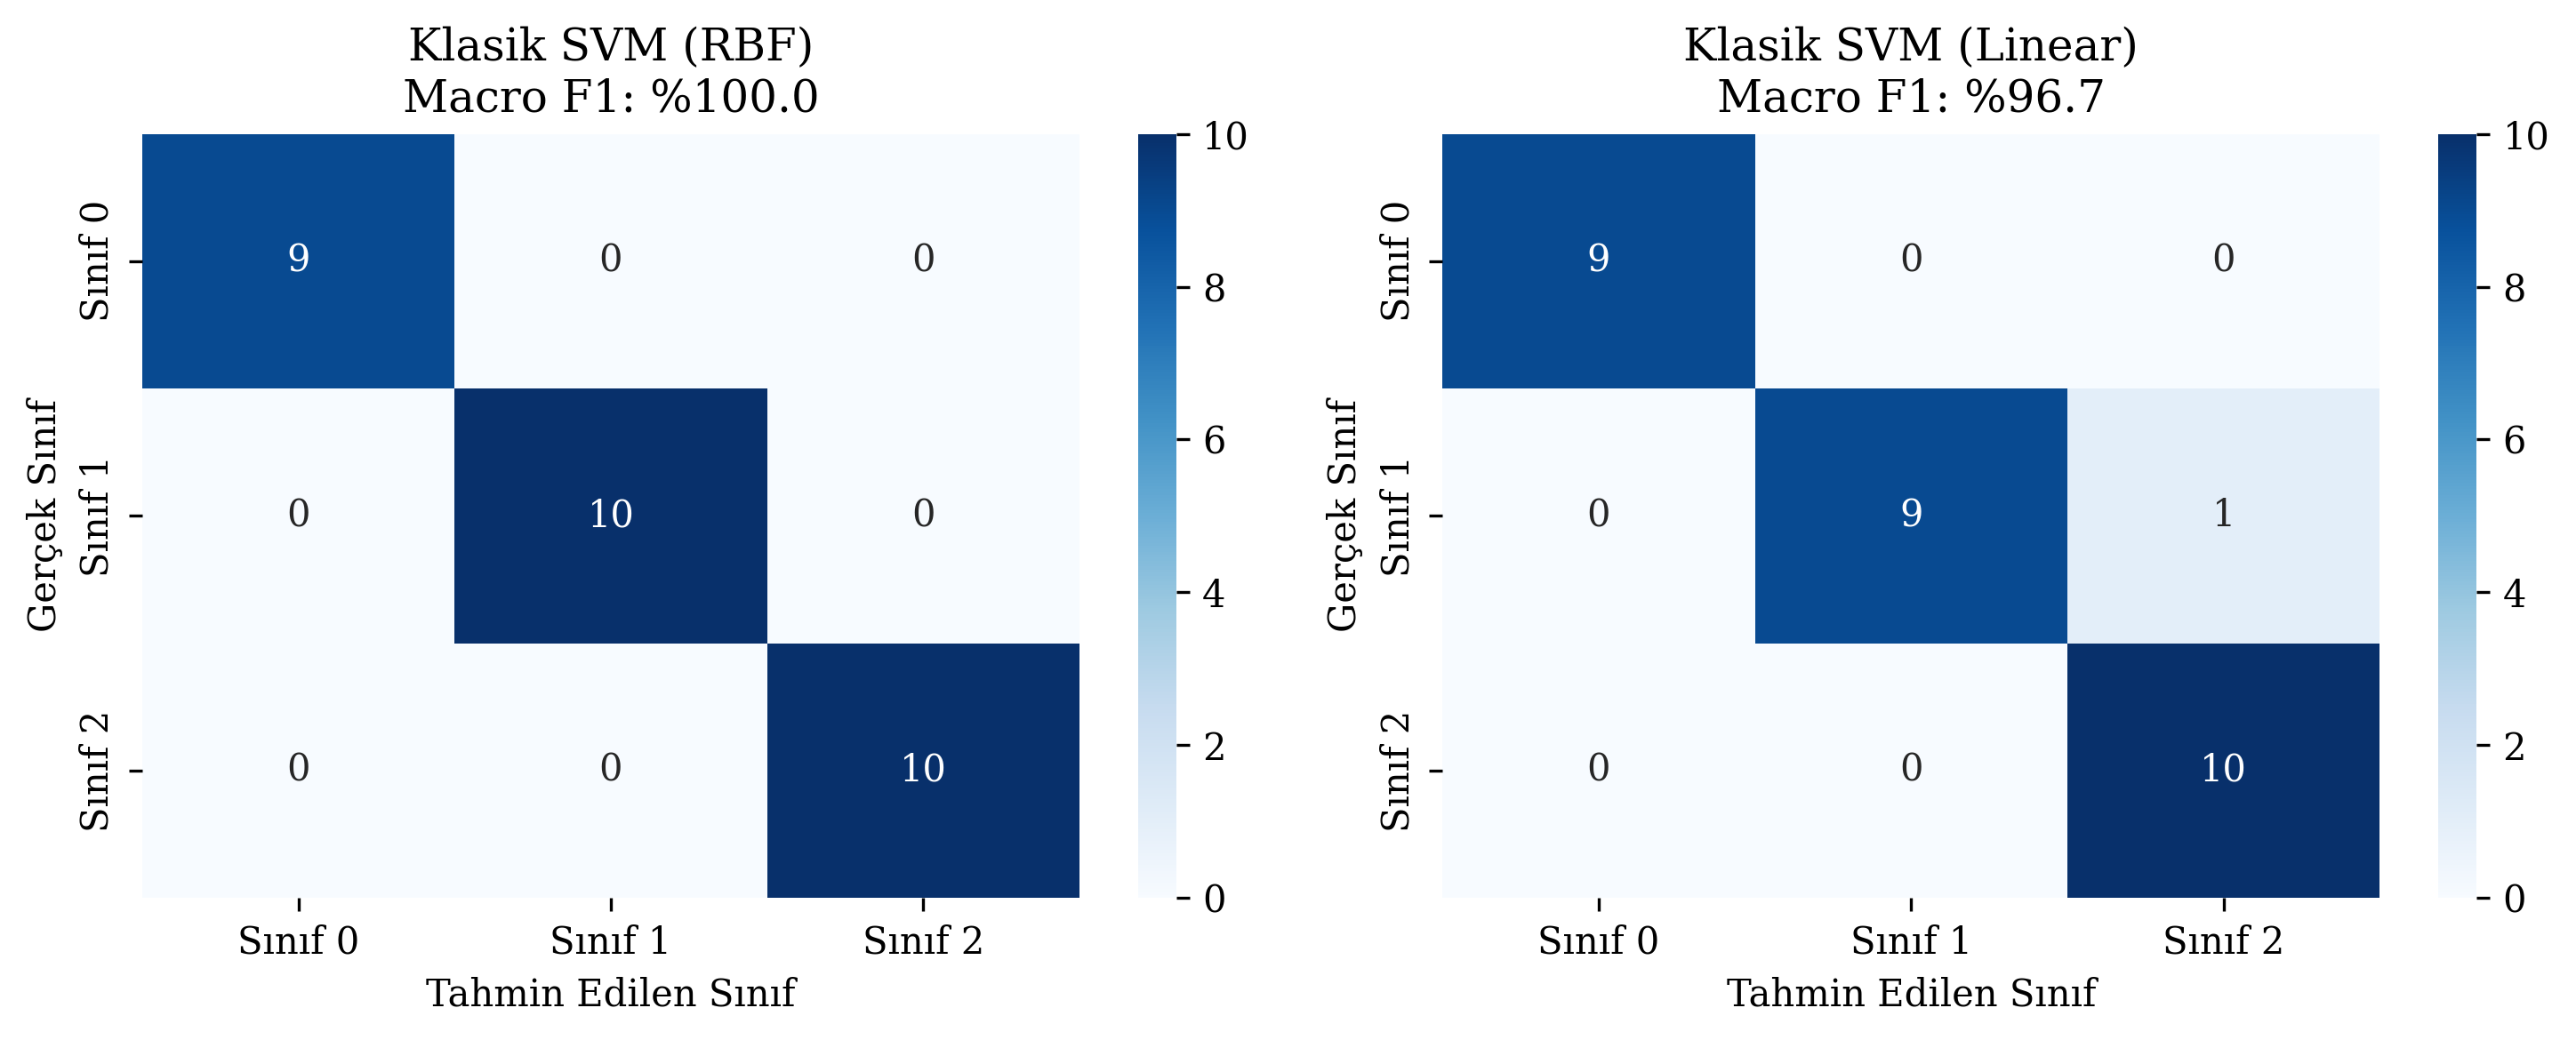

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

# ==========================================================
# 1. VERİ HAZIRLIĞI (HAKEM #2 YORUM #2: ŞEFFAF BÖLÜMLEME)
# ==========================================================
print("--- [KOD 1] KLASİK SVM DENEYLERİ BAŞLATILIYOR (WINE - 3 SINIF) ---")
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["Class"] = wine.target

# Dengeli alt örnekleme protokolü: Her sınıftan 48 örnek (Toplam: 144 örnek)
RANDOM_SEED = 42
n_samples_per_class = 48

c0 = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
c1 = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
c2 = df[df["Class"] == 2].sample(n=n_samples_per_class, random_state=RANDOM_SEED)

df_balanced = (
    pd.concat([c0, c1, c2])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

X_raw = df_balanced.drop(["Class"], axis=1).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Sınıf 0: {np.sum(y == 0)}, Sınıf 1: {np.sum(y == 1)}, Sınıf 2: {np.sum(y == 2)})")

# ==========================================================
# 2. VERİ BÖLME VE VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

pca_4d = PCA(n_components=4, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {explained_variance}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

# ==========================================================
# 3. İSTATİSTİKSEL ANALİZ: 5-FOLD STRATIFIED CV (HAKEM #2 YORUM #4)
# ==========================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro'
}

X_all_scaled = scaler.fit_transform(X_raw)
X_all_4d = pca_4d.fit_transform(X_all_scaled)
X_all_angles = minmax_scaler.fit_transform(X_all_4d)

cv_results_rbf = cross_validate(
    SVC(kernel="rbf", C=1.0, random_state=RANDOM_SEED),
    X_all_angles, y, cv=cv, scoring=scoring
)

cv_results_linear = cross_validate(
    SVC(kernel="linear", C=1.0, random_state=RANDOM_SEED),
    X_all_angles, y, cv=cv, scoring=scoring
)

# ==========================================================
# 4. KLASİK SVM (RBF & LINEAR) TEST SETİ PERFORMANSI
# ==========================================================
# A) RBF Kernel
start_t = time.time()
svm_rbf = SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_SEED)
svm_rbf.fit(X_train_angles, y_train)
time_train_rbf = time.time() - start_t

start_t = time.time()
preds_rbf = svm_rbf.predict(X_test_angles)
probs_rbf = svm_rbf.predict_proba(X_test_angles)
time_test_rbf = time.time() - start_t

acc_rbf = accuracy_score(y_test, preds_rbf)
f1_rbf_macro = f1_score(y_test, preds_rbf, average="macro")
auc_rbf = roc_auc_score(y_test, probs_rbf, multi_class="ovr")

# B) Linear Kernel
start_t = time.time()
svm_linear = SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_SEED)
svm_linear.fit(X_train_angles, y_train)
time_train_linear = time.time() - start_t

start_t = time.time()
preds_linear = svm_linear.predict(X_test_angles)
probs_linear = svm_linear.predict_proba(X_test_angles)
time_test_linear = time.time() - start_t

acc_linear = accuracy_score(y_test, preds_linear)
f1_linear_macro = f1_score(y_test, preds_linear, average="macro")
auc_linear = roc_auc_score(y_test, probs_linear, multi_class="ovr")

# ==========================================================
# 5. TABLOLAR VE ÇIKTILAR
# ==========================================================
print("=" * 85)
print(f"TEST SETİ PERFORMANSI (Hold-out Test: {len(y_test)} Örnek)")
print("=" * 85)
print(f"{'Model / Çekirdek':<22} | {'Doğruluk':<10} | {'F1 (Macro)':<12} | {'ROC-AUC':<10} | {'Süre (sn)'}")
print("-" * 85)
print(f"{'Klasik SVM (RBF)':<22} | %{acc_rbf*100:<8.2f} | %{f1_rbf_macro*100:<10.2f} | {auc_rbf:<10.4f} | {time_train_rbf+time_test_rbf:.4f} sn")
print(f"{'Klasik SVM (Linear)':<22} | %{acc_linear*100:<8.2f} | %{f1_linear_macro*100:<10.2f} | {auc_linear:<10.4f} | {time_train_linear+time_test_linear:.4f} sn")
print("=" * 85)

print("\n" + "=" * 85)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 85)
print(f"RBF    -> Doğruluk: %{cv_results_rbf['test_accuracy'].mean()*100:.2f} ± {cv_results_rbf['test_accuracy'].std()*100:.2f} | F1 (Macro): %{cv_results_rbf['test_f1_macro'].mean()*100:.2f} ± {cv_results_rbf['test_f1_macro'].std()*100:.2f}")
print(f"Linear -> Doğruluk: %{cv_results_linear['test_accuracy'].mean()*100:.2f} ± {cv_results_linear['test_accuracy'].std()*100:.2f} | F1 (Macro): %{cv_results_linear['test_f1_macro'].mean()*100:.2f} ± {cv_results_linear['test_f1_macro'].std()*100:.2f}")
print("=" * 85)

plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

labels = ["Sınıf 0", "Sınıf 1", "Sınıf 2"]

sns.heatmap(
    confusion_matrix(y_test, preds_rbf),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=labels,
    yticklabels=labels,
)
axes[0].set_title(f"Klasik SVM (RBF)\nMacro F1: %{f1_rbf_macro*100:.1f}")
axes[0].set_xlabel("Tahmin Edilen Sınıf")
axes[0].set_ylabel("Gerçek Sınıf")

sns.heatmap(
    confusion_matrix(y_test, preds_linear),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    xticklabels=labels,
    yticklabels=labels,
)
axes[1].set_title(f"Klasik SVM (Linear)\nMacro F1: %{f1_linear_macro*100:.1f}")
axes[1].set_xlabel("Tahmin Edilen Sınıf")
axes[1].set_ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig("svm_klasik_performans_wine.png", dpi=300)
plt.show()